In [ ]:
import torch
import torch.nn as nn
from tqdm import tqdm
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from torchvision.models import resnet18, ResNet18_Weights
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix
import warnings
warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=45),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.CIFAR10(root='.', train=True, download=True, transform=train_transform)
test_dataset = datasets.CIFAR10(root='.', train=False, download=True, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4, pin_memory=True)

print(f'train size: {len(train_dataset)}')
print(f'test size: {len(test_dataset)}')

img, label = train_dataset[0]
print(f"Iamge dimension: {img.shape}")
print(f'min value of a pixel: {img.min()}, max value of a pixel: {img.max()}')
print(f'Label: {label}')

100%|██████████| 170M/170M [31:22<00:00, 90.6kB/s]


train size: 50000
test size: 10000
Iamge dimension: torch.Size([3, 224, 224])
min value of a pixel: -2.1179039478302, max value of a pixel: 2.393557548522949
Label: 6


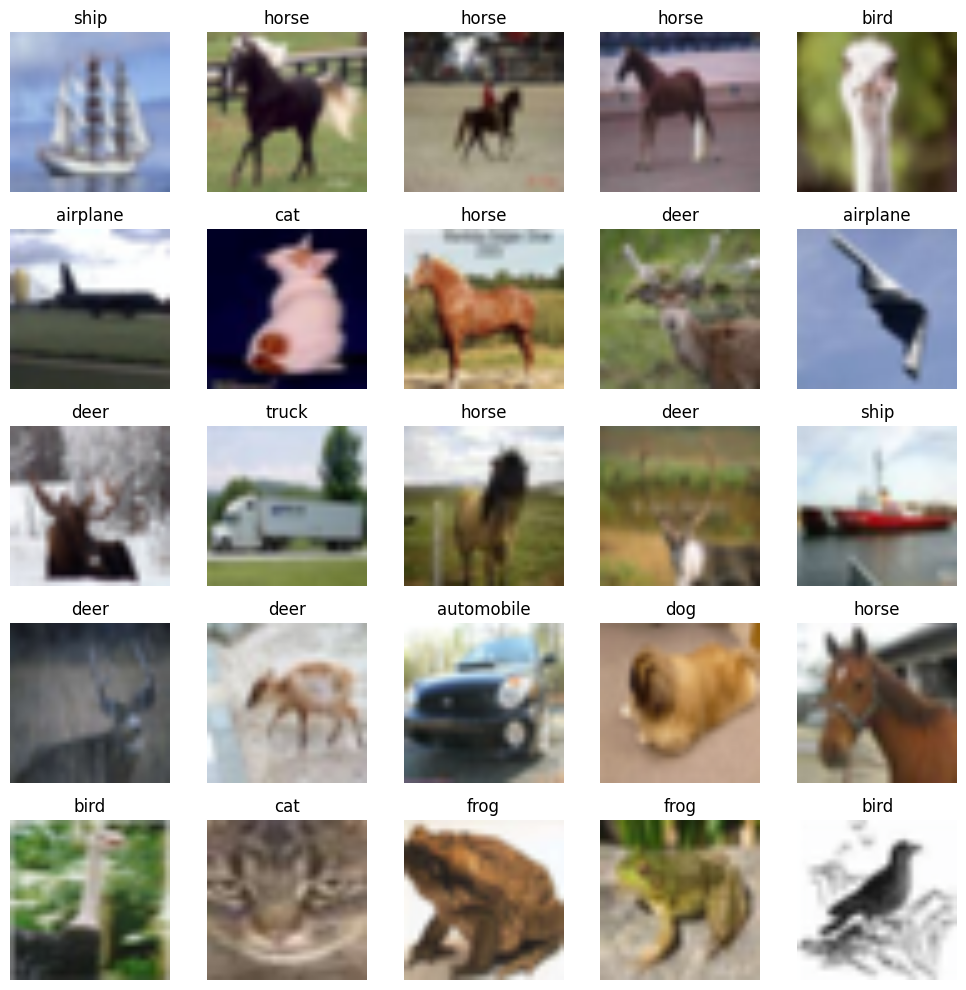

In [3]:
def imshow(img):
    img = img.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
figure = plt.figure(figsize=(10, 10))
cols, rows = 5, 5

for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(test_dataset), size=(1,)).item()
    img, label = test_dataset[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.axis("off")
    imshow(img)
    plt.title(class_names[label])
plt.tight_layout()
plt.show()

In [4]:
model = resnet18(weights=ResNet18_Weights.DEFAULT)

for param in model.parameters():
    param.requires_grad = False

num_ftrs = model.fc.in_features
model.fc = nn.Linear(in_features=num_ftrs, out_features=10)

model = model.to(device)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
scaler = torch.amp.GradScaler()

history = {'train_loss': [], 'test_loss': [], 'accuracy': []}
epochs = 5
best_acc = 0.0

for epoch in range(epochs):
    print(f"\\nEpoch {epoch+1}/{epochs}\\n{'-'*30}")
    model.train()
    train_loss = 0

    pbar = tqdm(train_loader, desc="Training")
    for x, y in pbar:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        with torch.cuda.amp.autocast():
            pred = model(x)
            loss = loss_function(pred, y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()
        pbar.set_postfix({'loss': f"{loss.item():.4f}"})

    avg_train_loss = train_loss / len(train_loader)

    model.eval()
    test_loss, correct = 0, 0

    with torch.no_grad():
        for x, y in tqdm(test_loader, desc="Testing "):
            x, y = x.to(device), y.to(device)
            pred = model(x)
            test_loss += loss_function(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    avg_test_loss = test_loss / len(test_loader)
    accuracy = 100 * correct / len(test_loader.dataset)

    history['train_loss'].append(avg_train_loss)
    history['test_loss'].append(avg_test_loss)
    history['accuracy'].append(accuracy)

    print(f"Train Loss: {avg_train_loss:.4f} | Test Loss: {avg_test_loss:.4f} | Accuracy: {accuracy:.2f}%")

    scheduler.step(avg_test_loss)

    if accuracy > best_acc:
        best_acc = accuracy
        torch.save(model.state_dict(), 'best_model.pth')
        print("--> Best model saved!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 158MB/s]


\nEpoch 1/5\n------------------------------


Testing : 100%|██████████| 157/157 [00:17<00:00,  9.07it/s]


Train Loss: 1.1741 | Test Loss: 0.8575 | Accuracy: 71.00%
--> Best model saved!
\nEpoch 2/5\n------------------------------


...

Train Loss: 0.9170 | Test Loss: 0.8164 | Accuracy: 72.52%
\nEpoch 4/5\n------------------------------


Testing : 100%|██████████| 157/157 [00:18<00:00,  8.52it/s]


Train Loss: 0.8895 | Test Loss: 0.8145 | Accuracy: 72.36%
\nEpoch 5/5\n------------------------------


Testing : 100%|██████████| 157/157 [00:17<00:00,  8.75it/s]


Train Loss: 0.8875 | Test Loss: 0.7253 | Accuracy: 75.17%
--> Best model saved!


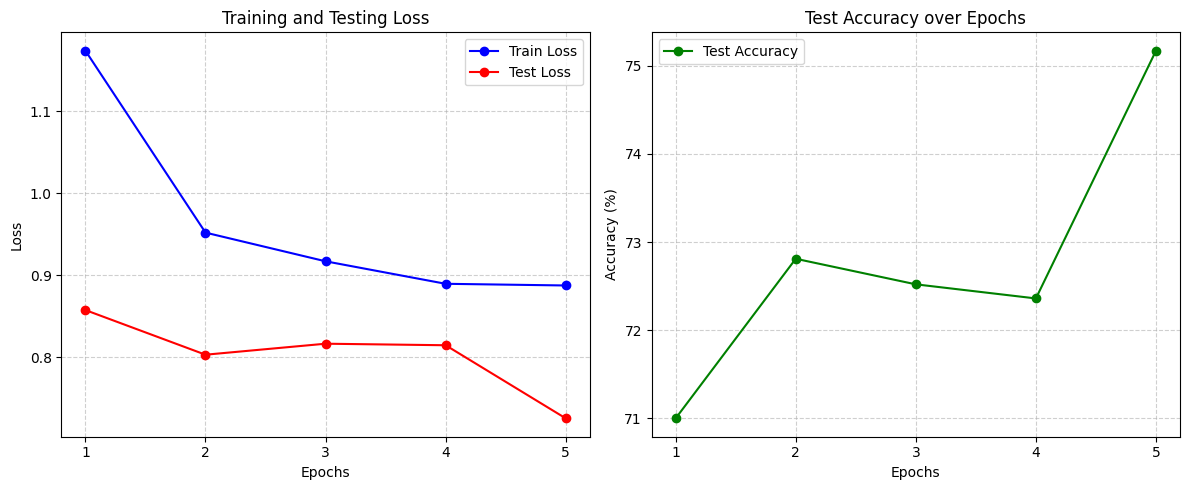

In [7]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs+1), history['train_loss'], label='Train Loss', marker='o', color='blue')
plt.plot(range(1, epochs+1), history['test_loss'], label='Test Loss', marker='o', color='red')
plt.title('Training and Testing Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.xticks(range(1, epochs+1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs+1), history['accuracy'], label='Test Accuracy', marker='o', color='green')
plt.title('Test Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.xticks(range(1, epochs+1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

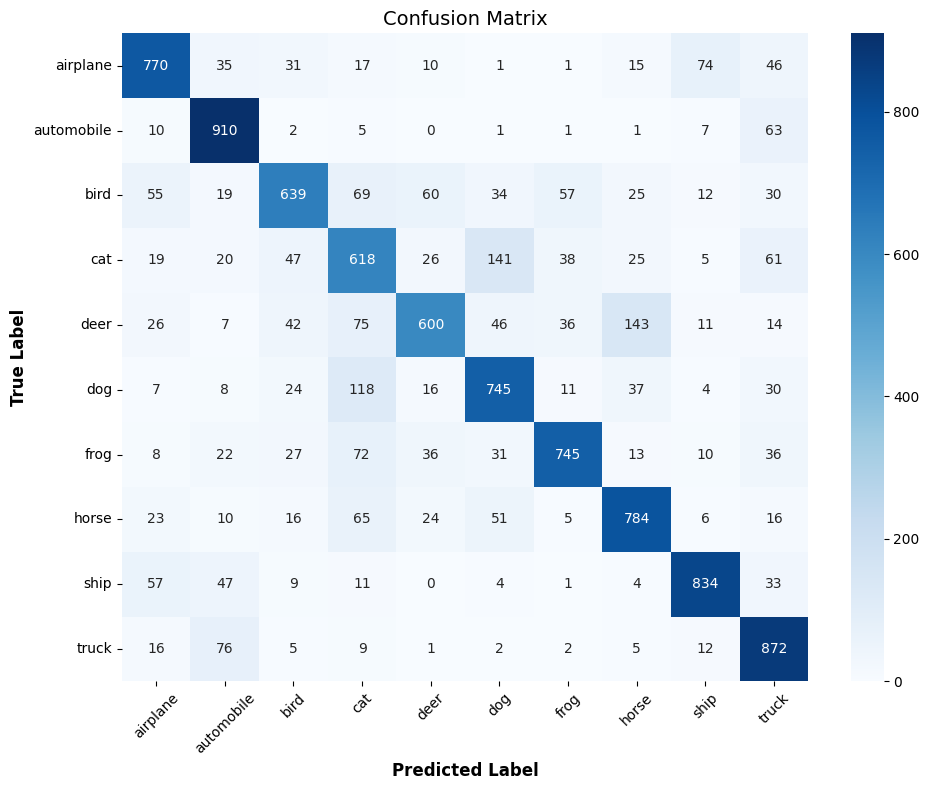

In [6]:
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        pred = model(x)
        preds = pred.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix', fontsize=14)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()